Ho voluto costruire questa analisi, basata sui dati della Banca Mondiale, con lo scopo e la curiosità di verificare se e come gli investimenti pubblici in istruzione si traducano in crescita del PIL. Attraverso modelli a ritardo temporale e panel data, il progetto vuole indagare la reale natura strutturale della spesa educativa

In [ ]:
import pandas as pd
import os

# Percorso alla cartella esatta sul Desktop
folder_path = os.path.expanduser('~/Desktop/Dataset progetto Data Manipulation')

# Percorsi completi dei tre file
p_gdp = os.path.join(folder_path, 'Spese in istruzione % PIL.csv')
p_gov = os.path.join(folder_path, 'Spese nazione in istruzione.csv')
p_macro = os.path.join(folder_path, 'crescita economica.csv')

# Caricamento dei dataset
df_gdp = pd.read_csv(p_gdp)
df_gov = pd.read_csv(p_gov)
df_macro = pd.read_csv(p_macro)

# Pulizia dei dati (rimozione NaN e standardizzazione tipi)
df_gdp_clean = df_gdp.dropna(subset=['value']).copy()
df_gov_clean = df_gov.dropna(subset=['value']).copy()
df_macro_clean = df_macro.dropna(subset=['value']).copy()

for df in [df_gdp_clean, df_gov_clean, df_macro_clean]:
    df['year'] = df['year'].astype(int)
    df['value'] = df['value'].astype(float)

print("--- TUTTI I DATI CARICATI E PULITI CON SUCCESSO! ---")
print("Righe pulite df_gdp:", len(df_gdp_clean))
print("Righe pulite df_gov:", len(df_gov_clean))
print("Righe pulite df_macro:", len(df_macro_clean))

--- TUTTI I DATI CARICATI E PULITI CON SUCCESSO! ---
Righe pulite df_gdp: 3538
Righe pulite df_gov: 2425
Righe pulite df_macro: 24990


In [ ]:
# 1. In questa fase filtro gli outlier macroscopici (es. errori di inserimento come Tuvalu 1997 e Zimbabwe 1994)
df_gdp_clean = df_gdp_clean[(df_gdp_clean['value'] > 0) & (df_gdp_clean['value'] <= 30)].copy()

# 2. Ricalcolo le statistiche reali 
mean_val = df_gdp_clean['value'].mean()
median_val = df_gdp_clean['value'].median()
std_val = df_gdp_clean['value'].std()
min_val = df_gdp_clean['value'].min()
max_val = df_gdp_clean['value'].max()
percentiles = df_gdp_clean['value'].quantile([0.10, 0.25, 0.50, 0.75, 0.90])

print("--- STATISTICHE PULITE: SPESA IN EDUCAZIONE (% PIL) ---")
print(f"Osservazioni valide: {len(df_gdp_clean)}")
print(f"Media globale: {mean_val:.2f}%")
print(f"Mediana globale: {median_val:.2f}%")
print(f"Deviazione standard: {std_val:.2f}")
print(f"Minimo: {min_val:.2f}% | Massimo: {max_val:.2f}%")
print("\nPercentili:")
print(percentiles)

--- STATISTICHE PULITE: SPESA IN EDUCAZIONE (% PIL) ---
Osservazioni valide: 3535
Media globale: 4.39%
Mediana globale: 4.29%
Deviazione standard: 1.83
Minimo: 0.70% | Massimo: 22.32%

Percentili:
0.10    2.170004
0.25    3.118240
0.50    4.294030
0.75    5.453370
0.90    6.505108
Name: value, dtype: float64


In [ ]:
# Classifica Top 10 e Bottom 10 Spender (media storica per paese)

# Controllo se ci sono aggregati regionali usando la lunghezza o i codici standard ISO-3
# Calcolo la media della spesa (% PIL) per ciascun paese, filtrando chi ha almeno 5 anni di rilevazioni
country_stats = df_gdp_clean.groupby(['country_code', 'country_name']).agg(
    media_spesa_pil=('value', 'mean'),
    anni_rilevati=('year', 'count')
).reset_index()

# Mantengo solo i paesi con una serie storica minima (es. almeno 5 rilevazioni) per evitare distorsioni da singoli anni isolati
country_stats_valid = country_stats[country_stats['anni_rilevati'] >= 5]

top_10 = country_stats_valid.sort_values(by='media_spesa_pil', ascending=False).head(10)
bottom_10 = country_stats_valid.sort_values(by='media_spesa_pil', ascending=True).head(10)

print("--- TOP 10 PAESI PER SPESA MEDIA IN ISTRUZIONE (% PIL) ---")
print(top_10[['country_name', 'country_code', 'media_spesa_pil', 'anni_rilevati']].to_string(index=False))

print("\n--- BOTTOM 10 PAESI PER SPESA MEDIA IN ISTRUZIONE (% PIL) ---")
print(bottom_10[['country_name', 'country_code', 'media_spesa_pil', 'anni_rilevati']].to_string(index=False))


--- TOP 10 PAESI PER SPESA MEDIA IN ISTRUZIONE (% PIL) ---
country_name country_code  media_spesa_pil  anni_rilevati
        Cuba          CUB         9.324694             17
     Lesotho          LSO         8.727555             22
 Timor-Leste          TLS         8.474134              7
    Zimbabwe          ZWE         8.258919             15
    Djibouti          DJI         8.116339             10
    Kiribati          KIR         7.706612              6
     Moldova          MDA         7.236071             16
     Denmark          DNK         7.183832             35
     Namibia          NAM         6.858834              8
 Puerto Rico          PRI         6.784614              9

--- BOTTOM 10 PAESI PER SPESA MEDIA IN ISTRUZIONE (% PIL) ---
            country_name country_code  media_spesa_pil  anni_rilevati
                  Monaco          MCO         1.211969             16
             South Sudan          SSD         1.409726              5
      West Bank and Gaza      

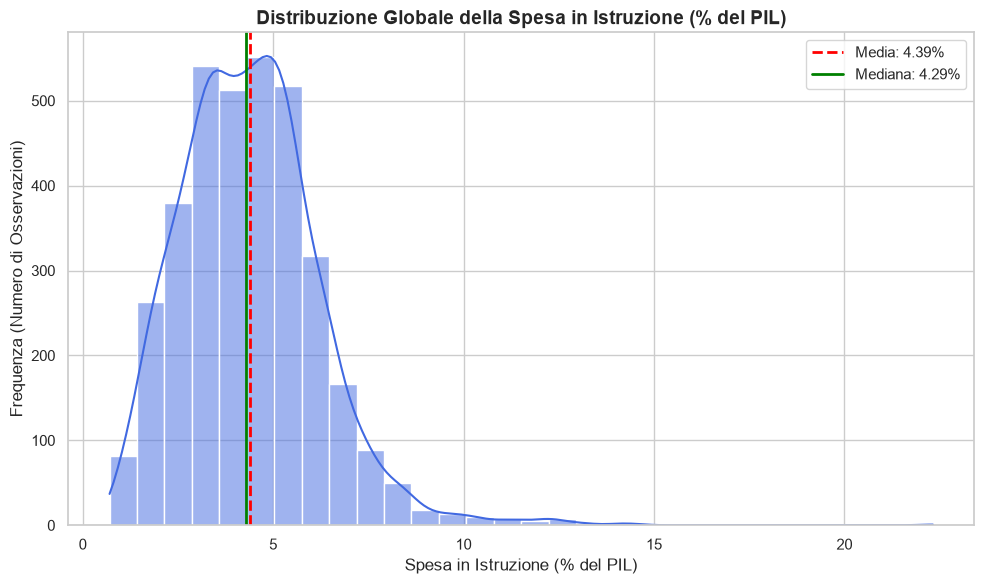

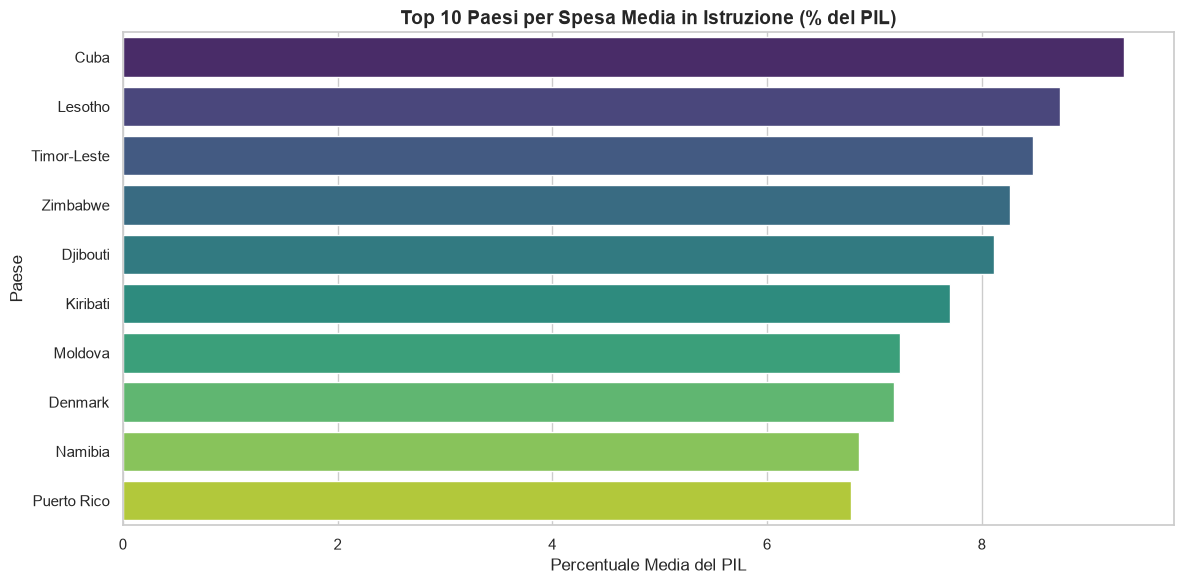

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Imposto in questa cella lo stile grafico di Seaborn
sns.set_theme(style="whitegrid")

# --- GRAFICO 1: Distribuzione della spesa in istruzione (% PIL) 
plt.figure(figsize=(10, 6))
sns.histplot(df_gdp_clean['value'], kde=True, color='royalblue', bins=30)
plt.title('Distribuzione Globale della Spesa in Istruzione (% del PIL)', fontsize=14, fontweight='bold')
plt.xlabel('Spesa in Istruzione (% del PIL)', fontsize=12)
plt.ylabel('Frequenza (Numero di Osservazioni)', fontsize=12)
plt.axvline(df_gdp_clean['value'].mean(), color='red', linestyle='--', linewidth=2, label=f'Media: {df_gdp_clean["value"].mean():.2f}%')
plt.axvline(df_gdp_clean['value'].median(), color='green', linestyle='-', linewidth=2, label=f'Mediana: {df_gdp_clean["value"].median():.2f}%')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# --- GRAFICO 2: Top 10 Paesi Spender 
plt.figure(figsize=(12, 6))
top_10_plot = country_stats_valid.sort_values(by='media_spesa_pil', ascending=False).head(10)
sns.barplot(x='media_spesa_pil', y='country_name', data=top_10_plot, palette='viridis', hue='country_name', legend=False)
plt.title('Top 10 Paesi per Spesa Media in Istruzione (% del PIL)', fontsize=14, fontweight='bold')
plt.xlabel('Percentuale Media del PIL', fontsize=12)
plt.ylabel('Paese', fontsize=12)
plt.tight_layout()
plt.show()

Osservazioni PIL Pro Capite: 12837
Osservazioni Crescita PIL (%): 12153

Osservazioni accoppiate valide per la crescita: 3384
Correlazione di Pearson (Spesa Istruzione vs Crescita % PIL): -0.1457


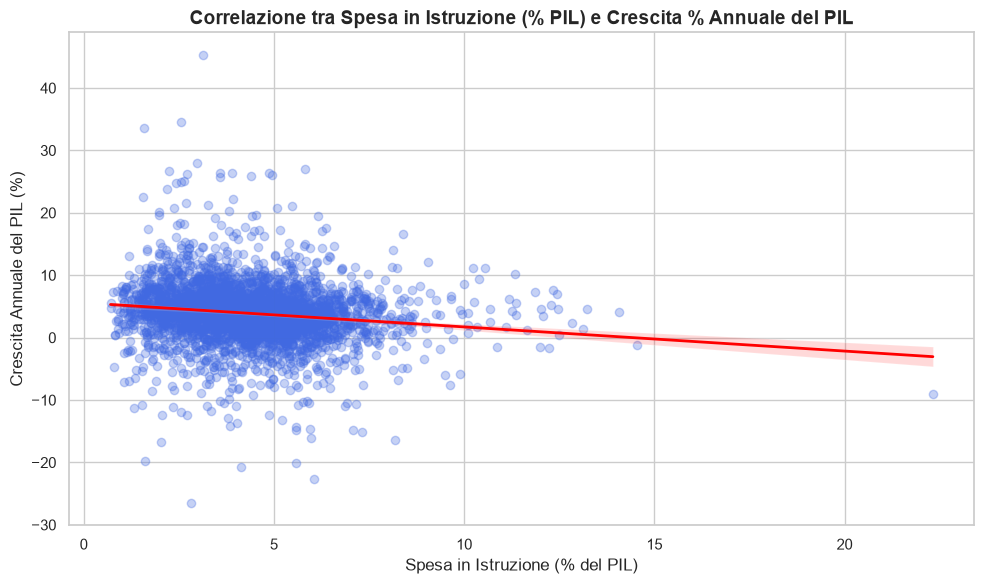

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Imposto lo stile grafico di Seaborn
sns.set_theme(style="whitegrid")

# 1. Separo il dataset macro nei due indicatori specifici
df_gdp_pc = df_macro_clean[df_macro_clean['indicator_code'] == 'NY.GDP.PCAP.CD'].copy()
df_gdp_growth = df_macro_clean[df_macro_clean['indicator_code'] == 'NY.GDP.MKTP.KD.ZG'].copy()

print(f"Osservazioni PIL Pro Capite: {len(df_gdp_pc)}")
print(f"Osservazioni Crescita PIL (%): {len(df_gdp_growth)}")

# 2. Unisco la spesa in istruzione con il tasso di crescita reale (GDP growth)
df_edu_subset = df_gdp_clean[['country_code', 'country_name', 'year', 'value']].rename(columns={'value': 'edu_exp_pct_gdp'})
df_growth_subset = df_gdp_growth[['country_code', 'year', 'value']].rename(columns={'value': 'gdp_growth_pct'})

df_merged_growth = pd.merge(df_edu_subset, df_growth_subset, on=['country_code', 'year'], how='inner').dropna()

# 3. Qui calcolo la correlazione di Pearson 
corr_growth = df_merged_growth['edu_exp_pct_gdp'].corr(df_merged_growth['gdp_growth_pct'], method='pearson')
print(f"\nOsservazioni accoppiate valide per la crescita: {len(df_merged_growth)}")
print(f"Correlazione di Pearson (Spesa Istruzione vs Crescita % PIL): {corr_growth:.4f}")

# 4. Creazione del grafico Scatter Plot con retta di regressione
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df_merged_growth, 
    x='edu_exp_pct_gdp', 
    y='gdp_growth_pct',
    scatter_kws={'alpha': 0.3, 'color': 'royalblue'},
    line_kws={'color': 'red', 'linewidth': 2}
)
plt.title('Correlazione tra Spesa in Istruzione (% PIL) e Crescita % Annuale del PIL', fontsize=14, fontweight='bold')
plt.xlabel('Spesa in Istruzione (% del PIL)', fontsize=12)
plt.ylabel('Crescita Annuale del PIL (%)', fontsize=12)
plt.tight_layout()
plt.show()


Osservazioni accoppiate valide per T+5 e T+10: 2007
Correlazione di Pearson (Spesa a t vs Crescita PIL a t+5): -0.0768
Correlazione di Pearson (Spesa a t vs Crescita PIL a t+10): -0.0967


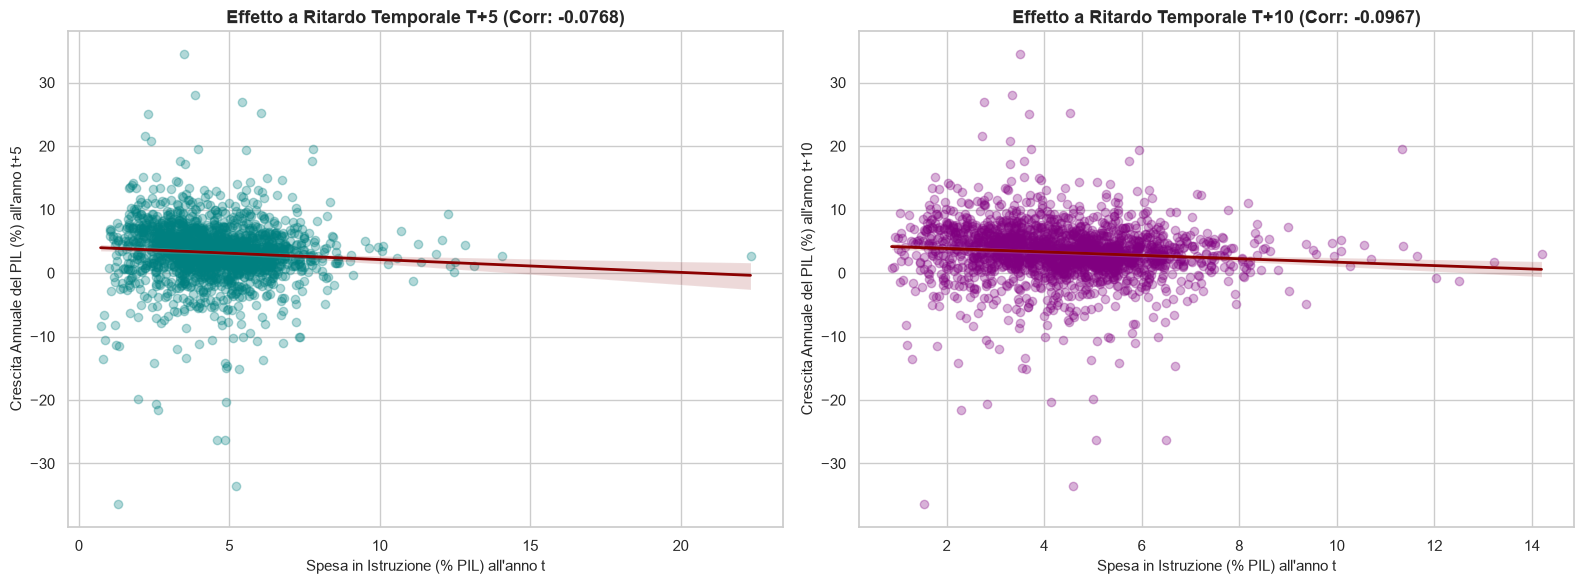

In [ ]:
# --- ANALISI A RITARDO TEMPORALE (TIME-LAGS T+5 e T+10) ---

# 1. Prima preparo i dataframe di base puliti direttamente dai dati filtrati
df_edu_base = df_gdp_clean[['country_code', 'year', 'value']].rename(columns={'value': 'edu_exp_pct_gdp'}).copy()
df_growth_base = df_gdp_growth[['country_code', 'year', 'value']].rename(columns={'value': 'gdp_growth_pct'}).copy()

# 2. Poi creo copie con gli anni traslati per la spesa in istruzione (T+5 e T+10)
df_edu_t5 = df_edu_base.copy()
df_edu_t5['year'] = df_edu_t5['year'] + 5
df_edu_t5 = df_edu_t5.rename(columns={'edu_exp_pct_gdp': 'edu_exp_t5'})

df_edu_t10 = df_edu_base.copy()
df_edu_t10['year'] = df_edu_t10['year'] + 10
df_edu_t10 = df_edu_t10.rename(columns={'edu_exp_pct_gdp': 'edu_exp_t10'})

# 3. Eseguo il merge basandomi su paese e anno ritardato
df_lagged = pd.merge(df_growth_base, df_edu_t5, on=['country_code', 'year'], how='inner')
df_lagged = pd.merge(df_lagged, df_edu_t10, on=['country_code', 'year'], how='inner')

# Pulizia dei valori nulli risultanti dai lag
df_lagged_clean = df_lagged.dropna().copy()

# 4. Calcolo delle correlazioni di Pearson per T+5 e T+10
corr_t5 = df_lagged_clean['edu_exp_t5'].corr(df_lagged_clean['gdp_growth_pct'], method='pearson')
corr_t10 = df_lagged_clean['edu_exp_t10'].corr(df_lagged_clean['gdp_growth_pct'], method='pearson')

print(f"Osservazioni accoppiate valide per T+5 e T+10: {len(df_lagged_clean)}")
print(f"Correlazione di Pearson (Spesa a t vs Crescita PIL a t+5): {corr_t5:.4f}")
print(f"Correlazione di Pearson (Spesa a t vs Crescita PIL a t+10): {corr_t10:.4f}")

# 5. Visualizzazione grafica con subplots affiancati (T+5 e T+10)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grafico T+5
sns.regplot(
    data=df_lagged_clean, x='edu_exp_t5', y='gdp_growth_pct',
    ax=axes[0], scatter_kws={'alpha': 0.3, 'color': 'teal'}, line_kws={'color': 'darkred', 'linewidth': 2}
)
axes[0].set_title(f'Effetto a Ritardo Temporale T+5 (Corr: {corr_t5:.4f})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Spesa in Istruzione (% PIL) all\'anno t', fontsize=11)
axes[0].set_ylabel('Crescita Annuale del PIL (%) all\'anno t+5', fontsize=11)

# Grafico T+10
sns.regplot(
    data=df_lagged_clean, x='edu_exp_t10', y='gdp_growth_pct',
    ax=axes[1], scatter_kws={'alpha': 0.3, 'color': 'purple'}, line_kws={'color': 'darkred', 'linewidth': 2}
)
axes[1].set_title(f'Effetto a Ritardo Temporale T+10 (Corr: {corr_t10:.4f})', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Spesa in Istruzione (% PIL) all\'anno t', fontsize=11)
axes[1].set_ylabel('Crescita Annuale del PIL (%) all\'anno t+10', fontsize=11)

plt.tight_layout()
plt.show()

--- CORRELAZIONE SPESA ISTRUZIONE VS CRESCITA % PIL PER FASCIA DI REDDITO ---
Fascia: Low Income / Developing | Osservazioni: 998 | Correlazione di Pearson: -0.0317
Fascia: Middle Income | Osservazioni: 1032 | Correlazione di Pearson: -0.1660
Fascia: High Income / Developed | Osservazioni: 1354 | Correlazione di Pearson: -0.2067


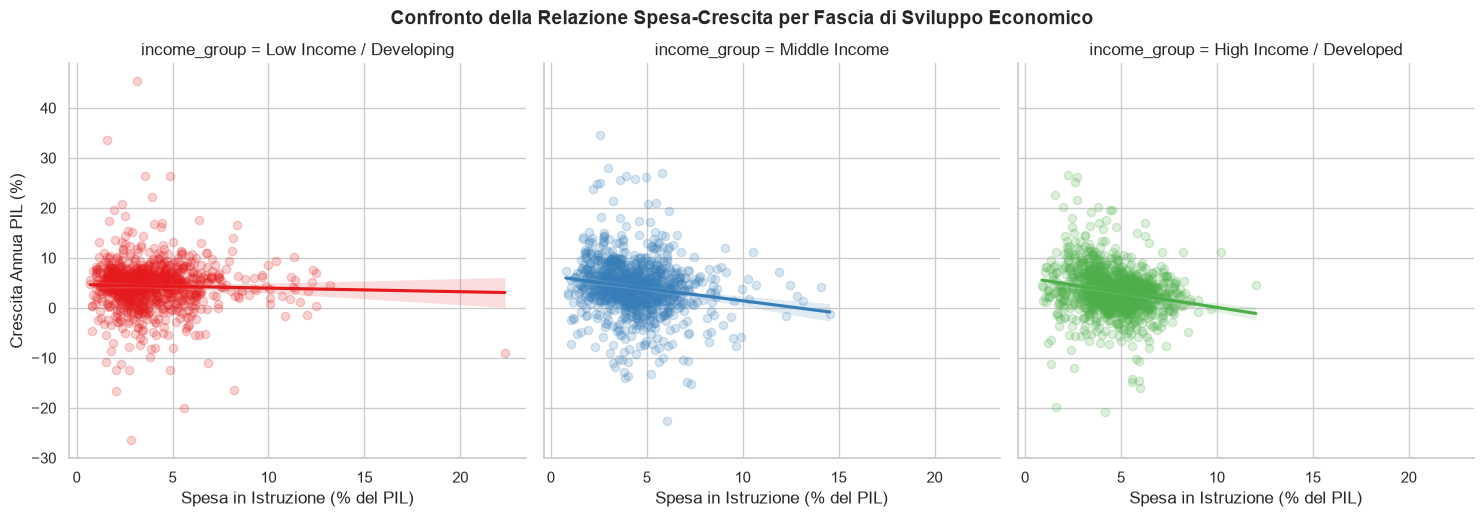

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- ANALISI PER FASCE DI REDDITO (BASATE SUL PIL PRO CAPITE) ---

# 1. Calcolo del PIL pro capite medio storico per ciascun paese per definirne la fascia economica
country_gdp_pc_mean = df_gdp_pc.groupby(['country_code', 'country_name'])['value'].mean().reset_index()
country_gdp_pc_mean = country_gdp_pc_mean.rename(columns={'value': 'mean_gdp_pc'})

# 2. Divisione dei paesi in 3 fasce di reddito (Tercili: Basso, Medio, Alto) usando i quantili (q=3)
country_gdp_pc_mean['income_group'] = pd.qcut(
    country_gdp_pc_mean['mean_gdp_pc'], 
    q=3, 
    labels=['Low Income / Developing', 'Middle Income', 'High Income / Developed']
)

# 3. Unisco questa classificazione al dataset unito della crescita (o dei lag)
df_growth_with_income = pd.merge(
    df_merged_growth, 
    country_gdp_pc_mean[['country_code', 'income_group']], 
    on='country_code', 
    how='inner'
).dropna(subset=['income_group'])

# 4. Individuo la correlazione di Pearson separatamente per ciascuna fascia di reddito
print("--- CORRELAZIONE SPESA ISTRUZIONE VS CRESCITA % PIL PER FASCIA DI REDDITO ---")
for group in df_growth_with_income['income_group'].unique():
    subset = df_growth_with_income[df_growth_with_income['income_group'] == group]
    corr_group = subset['edu_exp_pct_gdp'].corr(subset['gdp_growth_pct'], method='pearson')
    print(f"Fascia: {group} | Osservazioni: {len(subset)} | Correlazione di Pearson: {corr_group:.4f}")

# 5. Visualizzazione con FacetGrid di Seaborn per confrontare le rette di regressione
g = sns.lmplot(
    data=df_growth_with_income,
    x='edu_exp_pct_gdp',
    y='gdp_growth_pct',
    hue='income_group',
    col='income_group',
    scatter_kws={'alpha': 0.2},
    palette='Set1',
    height=5,
    aspect=1
)
g.set_axis_labels('Spesa in Istruzione (% del PIL)', 'Crescita Annua PIL (%)')
g.fig.suptitle('Confronto della Relazione Spesa-Crescita per Fascia di Sviluppo Economico', y=1.03, fontsize=14, fontweight='bold')
plt.show()

Paesi analizzati per la resilienza: 185
Correlazione (Volatilità Spesa Istruzione vs Crescita Media PIL): -0.0728


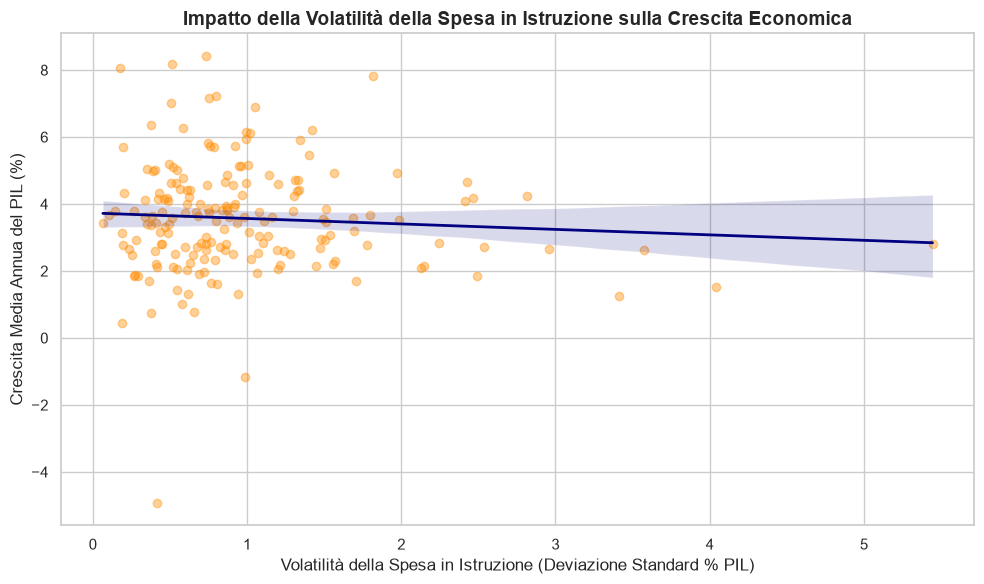

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- ANALISI 2: VOLATILITÀ DELLA SPESA IN ISTRUZIONE E PERFORMANCE ECONOMICA ---

# 1. Cerco la volatilità (deviazione standard) e la media della spesa in istruzione per ciascun paese
edu_volatility = df_gdp_clean.groupby(['country_code', 'country_name'])['value'].agg(['std', 'mean']).reset_index()
edu_volatility = edu_volatility.rename(columns={'std': 'edu_volatility', 'mean': 'edu_mean'})

# 2. Trovo la crescita media e la volatilità del PIL per ciascun paese
gdp_mean_perf = df_gdp_growth.groupby('country_code')['value'].agg(['mean', 'std']).reset_index()
gdp_mean_perf = gdp_mean_perf.rename(columns={'mean': 'gdp_growth_mean', 'std': 'gdp_growth_volatility'})

# 3. Unisco le metriche a livello di singolo paese
df_resilience = pd.merge(edu_volatility, gdp_mean_perf, on='country_code').dropna()

# 4. Calcolo la correlazione tra volatilità della spesa e crescita media del PIL
corr_vol_growth = df_resilience['edu_volatility'].corr(df_resilience['gdp_growth_mean'], method='pearson')
print(f"Paesi analizzati per la resilienza: {len(df_resilience)}")
print(f"Correlazione (Volatilità Spesa Istruzione vs Crescita Media PIL): {corr_vol_growth:.4f}")

# 5. Creazione del grafico Scatter Plot con retta di regressione
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df_resilience,
    x='edu_volatility',
    y='gdp_growth_mean',
    scatter_kws={'alpha': 0.4, 'color': 'darkorange'},
    line_kws={'color': 'navy', 'linewidth': 2}
)
plt.title('Impatto della Volatilità della Spesa in Istruzione sulla Crescita Economica', fontsize=14, fontweight='bold')
plt.xlabel('Volatilità della Spesa in Istruzione (Deviazione Standard % PIL)', fontsize=12)
plt.ylabel('Crescita Media Annua del PIL (%)', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import statsmodels.api as sm

# --- ANALISI PANEL DATA CON EFFETTI FISSI ---

# 1. Seleziono i dati puliti per l'analisi panel
df_fe = df_merged_growth[['country_code', 'year', 'edu_exp_pct_gdp', 'gdp_growth_pct']].dropna().copy()

# 2. Trasformazione Within-Group (Demeaned): sottraggo a ogni valore la media storica del rispettivo paese.
# Questo elimina completamente l'effetto fisso (eterogeneità) di ogni nazione.
df_fe['edu_demeaned'] = df_fe['edu_exp_pct_gdp'] - df_fe.groupby('country_code')['edu_exp_pct_gdp'].transform('mean')
df_fe['growth_demeaned'] = df_fe['gdp_growth_pct'] - df_fe.groupby('country_code')['gdp_growth_pct'].transform('mean')

# 3. Effettuo la regressione OLS sui dati "depurati" (Effetti Fissi per Paese)
X = sm.add_constant(df_fe['edu_demeaned'])
y = df_fe['growth_demeaned']
# Ho usato il modello OLS per tracciare la linea di tendenza che confronta ogni paese 
# con se stesso nel tempo per vedere l'effetto reale della spesa, 
# senza farsi ingannare dalle differenze fisse tra i vari Stati.
fe_model = sm.OLS(y, X).fit()

# 4. Stampo il sommario econometrico completo
print(fe_model.summary())

                            OLS Regression Results                            
Dep. Variable:        growth_demeaned   R-squared:                       0.026
Model:                            OLS   Adj. R-squared:                  0.025
Method:                 Least Squares   F-statistic:                     88.87
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           7.57e-21
Time:                        22:17:27   Log-Likelihood:                -9715.2
No. Observations:                3384   AIC:                         1.943e+04
Df Residuals:                    3382   BIC:                         1.945e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         2.776e-17      0.073   3.78e-16   

Dall'analisi è emerso che gli investimenti in istruzione non agiscono come uno stimolo economico di breve periodo, ma rappresentano una leva strutturale di lungo termine. I dati dimostrano che per incidere realmente sulla crescita serve continuità, stabilità di bilancio e qualità, ben oltre i semplici flussi di spesa annuali